# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Naufal Razzaq Mu'afa
- **Email:** naufalrazzaqmuafa@student.cs.unida.gontor.ac.id
- **ID Dicoding:** Naufal Razzaq Mu'afa

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:**
Berapa selisih rata-rata skor review antara order yang terlambat dan yang tepat waktu selama Januari 2017 - Agustus 2018, dan di state mana persentase keterlambatannya paling tinggi sehingga perbaikan logistik perlu diprioritaskan?
- **Pertanyaan 2:**
Kategori produk mana yang masuk 10 besar revenue pada Januari-Agustus 2018, dan bagaimana pertumbuhannya dibandingkan periode yang sama di 2017?
- ...

## Import Semua Packages/Library yang Digunakan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [ ]:
orders = pd.read_csv('data/orders_dataset.csv')
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
customers = pd.read_csv('data/customers_dataset.csv')
geolocation = pd.read_csv('data/geolocation_dataset.csv')
order_items = pd.read_csv('data/order_items_dataset.csv')
order_payments = pd.read_csv('data/order_payments_dataset.csv')
order_reviews = pd.read_csv('data/order_reviews_dataset.csv')
category_translation = pd.read_csv('data/product_category_name_translation.csv')
products = pd.read_csv('data/products_dataset.csv')
sellers = pd.read_csv('data/sellers_dataset.csv')

In [ ]:
for nama, df in {'orders': orders, 'customers': customers, 'geolocation': geolocation,
                 'order_items': order_items, 'order_payments': order_payments,
                 'order_reviews': order_reviews, 'category_translation': category_translation,
                 'products': products, 'sellers': sellers}.items():
    print(nama, df.shape)

orders (99441, 8)
customers (99441, 5)
geolocation (1000163, 5)
order_items (112650, 7)
order_payments (103886, 5)
order_reviews (99224, 7)
category_translation (71, 2)
products (32951, 9)
sellers (3095, 4)


**Insight:** (Opsional)
- Ada 9 tabel yang berhasil dimuat, dan semuanya saling terhubung lewat kolom kunci seperti `order_id`, `customer_id`, `product_id`, `seller_id`, dan kode pos.
- Data 'geolocation' adalah data yang paling besar, memiliki sekitar satu juta baris data.

### Assessing Data

#### Identifying missing values



In [ ]:
# Mengecek missing value di seluruh tabel

tabel = {'orders': orders, 'customers': customers, 'geolocation': geolocation,
         'order_items': order_items, 'order_payments': order_payments,
         'order_reviews': order_reviews, 'category_translation': category_translation,
         'products': products, 'sellers': sellers}

for nama, df in tabel.items():
    kosong = df.isna().sum()
    print(f'=== {nama} ===')
    print(kosong[kosong > 0] if kosong.sum() > 0 else 'Tidak ada missing value')
    print()

=== orders ===
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

=== customers ===
Tidak ada missing value

=== geolocation ===
Tidak ada missing value

=== order_items ===
Tidak ada missing value

=== order_payments ===
Tidak ada missing value

=== order_reviews ===
review_comment_title      87656
review_comment_message    58247
dtype: int64

=== category_translation ===
Tidak ada missing value

=== products ===
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

=== sellers ===
Tidak ada missing value



In [ ]:
# Identifikasi Missing Value (orders)

orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
# Mengecek Missing value di kolom tanggal (orders)

orders.groupby('order_status')[['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']].apply(lambda x: x.isna().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


#### Identifying data type

In [ ]:
# Mengecek tipe data (orders)

orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
# Mengecek tipe kolom tanggal di tabel 'order_reviews' dan 'order_items'

print(order_reviews[['review_creation_date', 'review_answer_timestamp']].dtypes)
print(order_items[['shipping_limit_date']].dtypes)

review_creation_date       object
review_answer_timestamp    object
dtype: object
shipping_limit_date    object
dtype: object


#### Identifying duplicated values

In [ ]:
# Mengecek duplicate values di semua tabel

for nama, df in tabel.items():
    print(nama, '->', df.duplicated().sum())

orders -> 0
customers -> 0
geolocation -> 261831
order_items -> 0
order_payments -> 0
order_reviews -> 0
category_translation -> 0
products -> 0
sellers -> 0


In [ ]:
# Mengecek apakah satu order punya lebih dari satu review

print('order_id yang muncul lebih dari sekali:', order_reviews['order_id'].duplicated().sum())

order_id yang muncul lebih dari sekali: 551


#### Identifying inconsistent values

In [ ]:
# Mengecek kategori produk yang tidak punya terjemahan

kategori_produk = set(products['product_category_name'].dropna())
kategori_terjemahan = set(category_translation['product_category_name'])
print('Kategori tanpa terjemahan:', kategori_produk - kategori_terjemahan)

Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


#### Identifying invalud values

In [ ]:
# Mengecek order delivered yang tanggal serah ke kurirnya LEBIH LAMBAT dari tanggal diterima pelanggan (Pertanyaan 1)

delivered = orders[orders['order_status'] == 'delivered']
tgl_kurir = pd.to_datetime(delivered['order_delivered_carrier_date'])
tgl_terima = pd.to_datetime(delivered['order_delivered_customer_date'])
print('Order dengan tanggal kurir setelah tanggal terima:', (tgl_kurir > tgl_terima).sum())

Order dengan tanggal kurir setelah tanggal terima: 23


In [ ]:
# Mengecek koordinat geolocation yang jatuh di luar wilayah Brasil (analisa geospasial)

di_luar_brasil = (~geolocation['geolocation_lat'].between(-34, 5.5)) | (~geolocation['geolocation_lng'].between(-74, -34))
print('Koordinat di luar wilayah Brasil:', di_luar_brasil.sum())

Koordinat di luar wilayah Brasil: 42


**Steps to Take:**
- Ada 23 order berstatus `delivered` yang tanggal serah ke kurirnya tercatat lebih lambat dari tanggal barang diterima pelanggan. Urutan ini jelas tidak mungkin terjadi. Karena kolom tanggal kurir tidak dipakai untuk menjawab pertanyaan bisnis, nilainya cukup dikosongkan saja. Order-nya tetap dipertahankan supaya jumlah data tidak berkurang tanpa alasan.

- Ditemukan 42 titik koordinat di tabel `geolocation` yang jatuh di luar wilayah Brasil, padahal semua pelanggan dan seller berada di sana. Titik-titik ini kemungkinan salah input, jadi akan dihapus supaya peta di analisis geospasial nanti tidak melenceng.

**Insight:** (Opsional)
- Dari penilaian ini, ditemukan lima jenis masalah: tipe data yang belum sesuai, missing value, data duplikat, nilai yang tidak konsisten, dan nilai yang tidak valid.
- Sebagian besar missing value ternyata wajar. Nilai kosong di kolom tanggal berasal dari order yang dibatalkan atau belum sampai, bukan karena data rusak.
- Masalah yang paling berpengaruh ke analisis adalah review ganda di `order_reviews`, karena bisa membuat skor rata-rata menjadi bias kalau tidak ditangani.
- Secara umum kualitas datanya cukup baik. Masalahnya berskala kecil dan bisa diperbaiki dengan aturan yang sederhana.

### Cleaning Data

#### Fixing data type problem

In [ ]:
# Mengubah kolom tanggal di tabel orders dari teks (object) menjadi datetime

kolom_tanggal_orders = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                        'order_delivered_customer_date', 'order_estimated_delivery_date']

for kolom in kolom_tanggal_orders:
    orders[kolom] = pd.to_datetime(orders[kolom])

In [ ]:
# Mengubah kolom tanggal di tabel order_reviews dan order_items menjadi datetime

order_reviews['review_creation_date'] = pd.to_datetime(order_reviews['review_creation_date'])
order_reviews['review_answer_timestamp'] = pd.to_datetime(order_reviews['review_answer_timestamp'])
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])

In [ ]:
# Memastikan tipe data sudah berubah

print(orders[kolom_tanggal_orders].dtypes)
print(order_reviews[['review_creation_date', 'review_answer_timestamp']].dtypes)
print(order_items[['shipping_limit_date']].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object
shipping_limit_date    datetime64[ns]
dtype: object


#### Fixing invalid value problem

In [ ]:
# Mengosongkan tanggal serah ke kurir yang lebih lambat dari tanggal diterima pelanggan

tgl_tidak_logis = orders['order_delivered_carrier_date'] > orders['order_delivered_customer_date']
print('Jumlah tanggal yang tidak logis:', tgl_tidak_logis.sum())

orders.loc[tgl_tidak_logis, 'order_delivered_carrier_date'] = pd.NaT

Jumlah tanggal yang tidak logis: 23


In [ ]:
# Verifikasi: seharusnya sudah tidak ada yang tersisa

print('Sisa setelah diperbaiki:', (orders['order_delivered_carrier_date'] > orders['order_delivered_customer_date']).sum())

Sisa setelah diperbaiki: 0


#### Fixing missing value problem

In [ ]:
# Mengambil hanya order delivered yang punya tanggal terima, hasilnya disimpan di variabel baru

orders_clean = orders[(orders['order_status'] == 'delivered') & orders['order_delivered_customer_date'].notna()].copy()

print('Jumlah order sebelum:', len(orders))
print('Jumlah order sesudah:', len(orders_clean))
print('Sisa nilai kosong di tanggal terima:', orders_clean['order_delivered_customer_date'].isna().sum())

Jumlah order sebelum: 99441
Jumlah order sesudah: 96470
Sisa nilai kosong di tanggal terima: 0


In [ ]:
# Mengisi produk tanpa kategori dengan label 'unknown'

products['product_category_name'] = products['product_category_name'].fillna('unknown')

print('Produk dengan kategori unknown:', (products['product_category_name'] == 'unknown').sum())
print('Sisa nilai kosong di kategori:', products['product_category_name'].isna().sum())

Produk dengan kategori unknown: 610
Sisa nilai kosong di kategori: 0


#### Fixing duplicate data problem

In [ ]:
# Satu order hanya menyimpan satu review, yaitu yang paling terakhir dijawab

print('Jumlah review sebelum:', len(order_reviews))

reviews_clean = (order_reviews.sort_values('review_answer_timestamp')
                 .drop_duplicates(subset='order_id', keep='last'))

print('Jumlah review sesudah:', len(reviews_clean))
print('order_id masih ada yang ganda?', reviews_clean['order_id'].duplicated().any())

Jumlah review sebelum: 99224
Jumlah review sesudah: 98673
order_id masih ada yang ganda? False


In [ ]:
# Menghapus baris duplikat di geolocation, lalu meringkasnya menjadi satu titik per kode pos

print('Jumlah baris sebelum:', len(geolocation))

geolocation_clean = geolocation.drop_duplicates()
print('Jumlah baris setelah hapus duplikat:', len(geolocation_clean))

geo_zip = (geolocation_clean.groupby('geolocation_zip_code_prefix')
           .agg(lat=('geolocation_lat', 'mean'),
                lng=('geolocation_lng', 'mean'),
                state=('geolocation_state', 'first'))
           .reset_index())

print('Jumlah titik per kode pos:', len(geo_zip))

Jumlah baris sebelum: 1000163
Jumlah baris setelah hapus duplikat: 738332
Jumlah titik per kode pos: 19015


#### Fixing inconsistent value problem

In [ ]:
# Menambahkan terjemahan untuk dua kategori yang tidak ada di tabel category_translation

terjemahan_tambahan = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_and_food_preparers']
})

category_translation_clean = pd.concat([category_translation, terjemahan_tambahan], ignore_index=True)

print('Jumlah kategori sebelum:', len(category_translation))
print('Jumlah kategori sesudah:', len(category_translation_clean))

Jumlah kategori sebelum: 71
Jumlah kategori sesudah: 73


In [ ]:
# Menggabungkan products dengan terjemahan kategori

products_clean = products.merge(category_translation_clean, on='product_category_name', how='left')

# Kategori 'unknown' tidak punya terjemahan, jadi diberi label unknown juga

products_clean['product_category_name_english'] = products_clean['product_category_name_english'].fillna('unknown')

print('Jumlah baris products:', len(products), '->', len(products_clean))
print('Jumlah kategori unik (termasuk unknown):', products_clean['product_category_name_english'].nunique())

Jumlah baris products: 32951 -> 32951
Jumlah kategori unik (termasuk unknown): 74


**Insight:** (Opsional)
- Semua masalah yang ditemukan di tahap Assessing sudah ditangani satu per satu, mulai dari tipe data, nilai yang tidak valid, missing value, duplikat, sampai nilai yang tidak konsisten.
- Kolom tanggal kini sudah bertipe `datetime`, jadi selisih waktu seperti keterlambatan pengiriman sudah bisa dihitung.
- Dari 99.441 order, tersisa 96.470 order berstatus `delivered` dengan tanggal terima yang lengkap. Hanya order inilah yang dipakai untuk analisis, karena order yang dibatalkan atau belum sampai memang tidak punya cerita pengiriman yang bisa dinilai.
- Review ganda sudah dirapikan sehingga tiap order hanya punya satu review (yang terbaru), dari 99.224 menjadi 98.673 baris. Dengan begitu skor rata-rata tidak lagi bias saat tabel digabung.
- Tabel `geolocation` yang awalnya sekitar satu juta baris kini diringkas menjadi sekitar 19 ribu titik, satu per kode pos. Ukurannya jauh lebih ringan dan siap dipakai untuk analisis geospasial.
- Dua kategori produk yang tadinya tidak punya terjemahan sudah dilengkapi, dan produk tanpa kategori diberi label `unknown` supaya tetap ikut terhitung dalam analisis revenue.

## Exploratory Data Analysis (EDA)

### Explore data keterlambatan dan skor review (Pertanyaan 1)

In [ ]:
# Membatasi order pada periode analisis: Januari 2017 - Agustus 2018

orders_periode = orders_clean[orders_clean['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')].copy()

print('Jumlah order sebelum dibatasi periode:', len(orders_clean))
print('Jumlah order dalam periode analisis:', len(orders_periode))

Jumlah order sebelum dibatasi periode: 96470
Jumlah order dalam periode analisis: 96203


In [ ]:
# Menggabungkan order dengan state pelanggan dan skor review

df_q1 = (orders_periode
         .merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
         .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left'))

print('Ukuran tabel gabungan:', df_q1.shape)
print('Order tanpa review:', df_q1['review_score'].isna().sum())
df_q1.head()

Ukuran tabel gabungan: (96203, 10)
Order tanpa review: 643


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,GO,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,RN,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,SP,5.0


In [ ]:
# Order dianggap terlambat jika tanggal diterima lebih lambat dari tanggal estimasi

df_q1['terlambat'] = df_q1['order_delivered_customer_date'] > df_q1['order_estimated_delivery_date']
df_q1['status_kirim'] = df_q1['terlambat'].map({True: 'Terlambat', False: 'Tepat waktu'})

print('Jumlah order terlambat:', df_q1['terlambat'].sum())
print('Persentase terlambat:', round(df_q1['terlambat'].mean() * 100, 2), '%')

Jumlah order terlambat: 7822
Persentase terlambat: 8.13 %


In [ ]:
# Membandingkan jumlah order dan rata-rata skor review antara order terlambat dan tepat waktu

ringkasan_skor = (df_q1.groupby('status_kirim')
                  .agg(jumlah_order=('order_id', 'count'),
                       rata_skor=('review_score', 'mean'))
                  .round(2))
ringkasan_skor

,jumlah_order,rata_skor
status_kirim,,
Tepat waktu,88381,4.29
Terlambat,7822,2.57


In [ ]:
# Selisih rata-rata skor antara order tepat waktu dan terlambat

selisih = ringkasan_skor.loc['Tepat waktu', 'rata_skor'] - ringkasan_skor.loc['Terlambat', 'rata_skor']
print('Selisih rata-rata skor review:', round(selisih, 2))

Selisih rata-rata skor review: 1.72


In [ ]:
# Menghitung jumlah order, jumlah terlambat, dan persentase keterlambatan per state

per_state = (df_q1.groupby('customer_state')
             .agg(total_order=('order_id', 'count'),
                  order_terlambat=('terlambat', 'sum'))
             .reset_index())

per_state['persen_terlambat'] = (per_state['order_terlambat'] / per_state['total_order'] * 100).round(2)

print('Jumlah state:', len(per_state))
per_state.sort_values('total_order').head()

Jumlah state: 27


,customer_state,total_order,order_terlambat,persen_terlambat
21,RR,40,5,12.50
3,AP,67,3,4.48
0,AC,80,3,3.75
2,AM,145,6,4.14
20,RO,243,7,2.88


In [ ]:
# Peringkat state dengan keterlambatan tertinggi, hanya state dengan minimal 100 order

state_valid = per_state[per_state['total_order'] >= 100]

print('State yang masuk peringkat:', len(state_valid), 'dari', len(per_state))
state_valid.sort_values('persen_terlambat', ascending=False).head(10)

State yang masuk peringkat: 24 dari 27


,customer_state,total_order,order_terlambat,persen_terlambat
1,AL,396,95,23.99
9,MA,713,140,19.64
16,PI,475,76,16.00
5,CE,1273,196,15.40
24,SE,332,51,15.36
4,BA,3253,457,14.05
18,RJ,12310,1664,13.52
26,TO,274,35,12.77
13,PA,942,117,12.42
7,ES,1992,244,12.25


### Explore revenue kategori produk (Pertanyaan 2)

In [ ]:
# Menggabungkan item order dengan kategori produk (nama Inggris)

df_q2 = (orders_periode[['order_id', 'order_purchase_timestamp']]
         .merge(order_items[['order_id', 'product_id', 'price']], on='order_id', how='inner')
         .merge(products_clean[['product_id', 'product_category_name_english']], on='product_id', how='left'))

df_q2['tahun'] = df_q2['order_purchase_timestamp'].dt.year
df_q2['bulan'] = df_q2['order_purchase_timestamp'].dt.month

print('Ukuran tabel:', df_q2.shape)
print('Total revenue (price):', round(df_q2['price'].sum(), 2))
print('Item tanpa kategori:', df_q2['product_category_name_english'].isna().sum())

Ukuran tabel: (109872, 7)
Total revenue (price): 13179777.95
Item tanpa kategori: 0


In [ ]:
# Revenue periode yang sama (Januari-Agustus) di 2017 dan 2018

df_jan_agu = df_q2[df_q2['bulan'] <= 8]

print(df_jan_agu.groupby('tahun')['price'].sum().round(2))

tahun
2017    2993277.13
2018    7217172.24
Name: price, dtype: float64


In [ ]:
# Revenue per kategori per tahun, lalu ambil 10 besar 2018 beserta pertumbuhannya

rev_kategori = df_jan_agu.pivot_table(index='product_category_name_english',
                                      columns='tahun', values='price',
                                      aggfunc='sum', fill_value=0)
rev_kategori.columns = ['revenue_2017', 'revenue_2018']

top10 = rev_kategori.sort_values('revenue_2018', ascending=False).head(10).copy()
top10['pertumbuhan_persen'] = ((top10['revenue_2018'] - top10['revenue_2017']) / top10['revenue_2017'] * 100).round(1)
top10.round(0)

,revenue_2017,revenue_2018,pertumbuhan_persen
product_category_name_english,,,
health_beauty,243522.0,755724.0,210.0
watches_gifts,201138.0,687577.0,242.0
bed_bath_table,254445.0,532359.0,109.0
sports_leisure,216545.0,517166.0,139.0
computers_accessories,214631.0,496158.0,131.0
housewares,127535.0,391823.0,207.0
furniture_decor,170859.0,381650.0,123.0
auto,125247.0,343288.0,174.0
baby,67998.0,250616.0,269.0


**Insight:** (Opsional)
**Insight:**

*Pertanyaan 1: keterlambatan dan skor review*
- Dari 96.203 order yang dianalisis (Januari 2017 - Agustus 2018), sebanyak 7.822 order (sekitar 8,13%) tiba lebih lambat dari estimasi. Artinya sebagian besar pesanan sampai tepat waktu, tapi jumlah yang terlambat tetap tidak sedikit.
- Dampaknya ke kepuasan pelanggan cukup terasa. Order yang tepat waktu rata-rata mendapat skor 4,29, sedangkan order yang terlambat hanya 2,57. Selisihnya sekitar 1,72 poin pada skala 1-5.
- Keterlambatan tidak tersebar merata. Setelah dibatasi pada state dengan minimal 100 order, Alagoas (AL) berada di urutan teratas dengan sekitar 24% ordernya terlambat. Di belakangnya ada Maranhão (MA) sekitar 19,6%, Piauí (PI) 16%, Ceará (CE) 15,4%, dan Sergipe (SE) 15,4%. Semuanya jauh di atas rata-rata keseluruhan.
- State dengan order sangat sedikit (misalnya RR yang hanya 40 order) sengaja tidak dimasukkan ke peringkat, karena persentasenya mudah bergeser hanya oleh satu-dua order.

*Pertanyaan 2: revenue kategori produk*
- Pada Januari-Agustus 2018, kategori dengan revenue terbesar adalah `health_beauty` (sekitar 756 ribu), disusul `watches_gifts` (sekitar 688 ribu) dan `bed_bath_table` (sekitar 532 ribu).
- Total revenue periode yang sama naik dari sekitar 2,99 juta di 2017 menjadi 7,22 juta di 2018, atau naik sekitar 141%. Jadi kenaikan besar di banyak kategori sebagian besar mencerminkan marketplace yang sedang membesar, bukan prestasi satu kategori saja.
- Dibandingkan dengan pertumbuhan keseluruhan itu, beberapa kategori tumbuh lebih cepat, seperti `baby` (sekitar 269%), `watches_gifts` (242%), dan `health_beauty` (210%). Sebaliknya `bed_bath_table` tumbuh lebih lambat (109%), dan `cool_stuff` nyaris stagnan (sekitar 10%) meski masih masuk 10 besar.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Berapa selisih rata-rata skor review antara order yang terlambat dan tepat waktu, dan di state mana keterlambatannya paling tinggi?

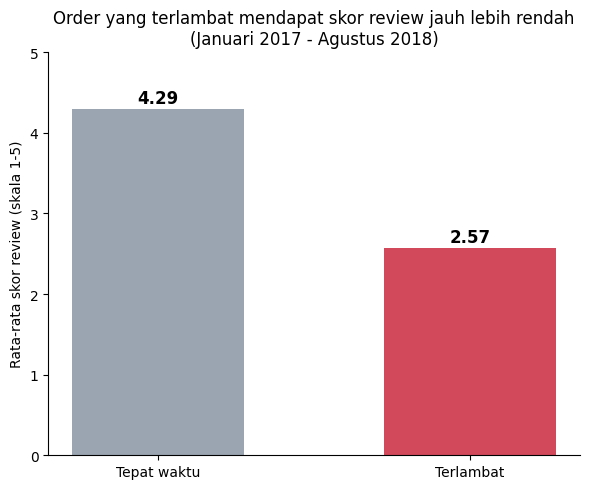

In [ ]:
# Grafik 1: rata-rata skor review, order tepat waktu vs terlambat

urutan = ['Tepat waktu', 'Terlambat']
warna = {'Tepat waktu': '#9AA5B1', 'Terlambat': '#D1495B'}

fig, ax = plt.subplots(figsize=(6, 5))
nilai = ringkasan_skor.loc[urutan, 'rata_skor']
batang = ax.bar(urutan, nilai, color=[warna[s] for s in urutan], width=0.55)

for b, v in zip(batang, nilai):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.08, f'{v:.2f}', ha='center', fontsize=12, fontweight='bold')

ax.set_ylim(0, 5)
ax.set_ylabel('Rata-rata skor review (skala 1-5)')
ax.set_title('Order yang terlambat mendapat skor review jauh lebih rendah\n(Januari 2017 - Agustus 2018)', fontsize=12)
sns.despine()
plt.tight_layout()
plt.show()

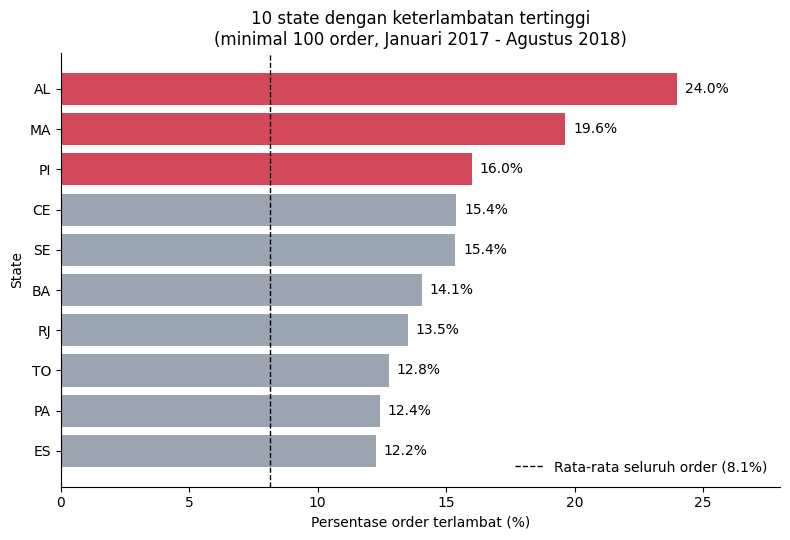

In [ ]:
# Grafik 2: 10 state dengan persentase keterlambatan tertinggi (minimal 100 order)

top_state = state_valid.sort_values('persen_terlambat', ascending=False).head(10)
rata_rata = df_q1['terlambat'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
warna_bar = ['#D1495B' if i < 3 else '#9AA5B1' for i in range(len(top_state))]
ax.barh(top_state['customer_state'], top_state['persen_terlambat'], color=warna_bar)
ax.invert_yaxis()

for i, v in enumerate(top_state['persen_terlambat']):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=10)

ax.axvline(rata_rata, color='black', linestyle='--', linewidth=1, label=f'Rata-rata seluruh order ({rata_rata:.1f}%)')
ax.legend(loc='lower right', frameon=False)

ax.set_xlabel('Persentase order terlambat (%)')
ax.set_ylabel('State')
ax.set_title('10 state dengan keterlambatan tertinggi\n(minimal 100 order, Januari 2017 - Agustus 2018)', fontsize=12)
ax.set_xlim(0, top_state['persen_terlambat'].max() + 4)
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Kategori produk mana yang masuk 10 besar revenue pada Januari-Agustus 2018, dan bagaimana pertumbuhannya dibanding periode yang sama di 2017?

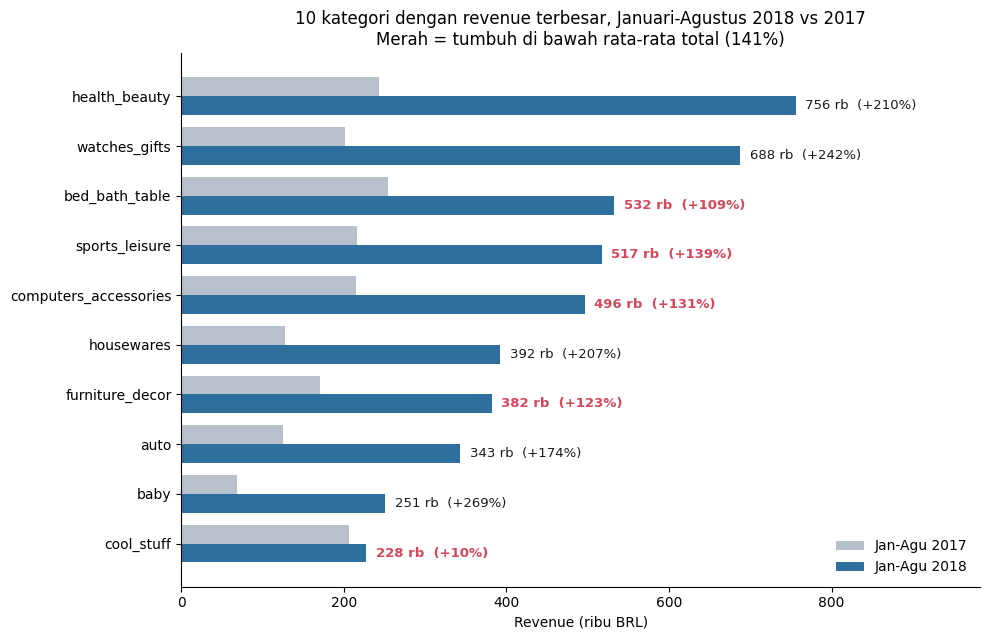

In [ ]:
# Grafik 3: 10 kategori dengan revenue terbesar, Jan-Agu 2018 dibanding Jan-Agu 2017

total_2017 = df_jan_agu[df_jan_agu['tahun'] == 2017]['price'].sum()
total_2018 = df_jan_agu[df_jan_agu['tahun'] == 2018]['price'].sum()
pertumbuhan_total = (total_2018 - total_2017) / total_2017 * 100

data_plot = top10.sort_values('revenue_2018')   # diurutkan agar terbesar berada di atas
y = np.arange(len(data_plot))
tinggi = 0.38

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(y + tinggi / 2, data_plot['revenue_2017'] / 1000, height=tinggi, color='#B8C0CC', label='Jan-Agu 2017')
ax.barh(y - tinggi / 2, data_plot['revenue_2018'] / 1000, height=tinggi, color='#2E6F9E', label='Jan-Agu 2018')

for i, (rev18, growth) in enumerate(zip(data_plot['revenue_2018'], data_plot['pertumbuhan_persen'])):
    warna_teks = '#D1495B' if growth < pertumbuhan_total else '#1B1B1B'
    ax.text(rev18 / 1000 + 12, i - tinggi / 2, f'{rev18/1000:,.0f} rb  (+{growth:.0f}%)',
            va='center', fontsize=9.5, color=warna_teks, fontweight='bold' if growth < pertumbuhan_total else 'normal')

ax.set_yticks(y)
ax.set_yticklabels(data_plot.index)
ax.set_xlabel('Revenue (ribu BRL)')
ax.set_title('10 kategori dengan revenue terbesar, Januari-Agustus 2018 vs 2017\n'
             f'Merah = tumbuh di bawah rata-rata total ({pertumbuhan_total:.0f}%)', fontsize=12)
ax.set_xlim(0, data_plot['revenue_2018'].max() / 1000 * 1.3)
ax.legend(loc='lower right', frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
**Insight:**

*Pertanyaan 1: keterlambatan dan skor review*
- Dari grafiknya kelihatan jelas bahwa telat kirim itu mahal harganya. Pesanan yang sampai tepat waktu rata-rata dapat skor 4,29, sementara yang telat cuma 2,57. Selisihnya hampir 1,7 poin, jadi pelanggan yang menunggu lebih lama memang jauh lebih kecewa.
- Soal di mana masalahnya paling parah, jawabannya ada di Alagoas (24,0%), lalu Maranhão (19,6%) dan Piauí (16,0%). Angka itu jauh di atas rata-rata keseluruhan yang hanya 8,1%, artinya di tiga state ini sekitar satu dari empat sampai satu dari enam pesanan datang terlambat.
- Menariknya, enam dari sepuluh state teratas ada di kawasan Timur Laut Brasil (AL, MA, PI, CE, SE, dan BA). Jadi keterlambatan ini kelihatannya bukan kebetulan, tapi menumpuk di satu wilayah yang sama.

*Pertanyaan 2: revenue kategori produk*
- Untuk Januari-Agustus 2018, `health_beauty` jadi juara dengan revenue sekitar 756 ribu BRL. Di belakangnya ada `watches_gifts` dan `bed_bath_table`.
- Sebelum merasa semua kategori hebat, perlu diingat bahwa revenue seluruh marketplace memang naik sekitar 141%. Dengan patokan itu, lima dari sepuluh kategori teratas sebenarnya tumbuh lebih lambat dari pasar: `bed_bath_table`, `sports_leisure`, `computers_accessories`, `furniture_decor`, dan `cool_stuff`.
- Yang paling mencuri perhatian adalah `cool_stuff`, yang hanya naik sekitar 10% dan nyaris jalan di tempat. Di sisi lain, `baby` (sekitar 269%) dan `watches_gifts` (sekitar 242%) melesat jauh melampaui rata-rata.

### Analisis Geospasial: sebaran keterlambatan pengiriman per state

In [ ]:
# Menentukan titik pusat tiap state dari rata-rata koordinat kode posnya

pusat_state = geo_zip.groupby('state').agg(lat=('lat', 'mean'), lng=('lng', 'mean')).reset_index()

# Menggabungkan dengan data keterlambatan per state (dari tahap EDA)

peta_state = per_state.merge(pusat_state, left_on='customer_state', right_on='state', how='left')

print('State di peta:', len(peta_state))
print('State tanpa koordinat:', peta_state['lat'].isna().sum())

State di peta: 27
State tanpa koordinat: 0


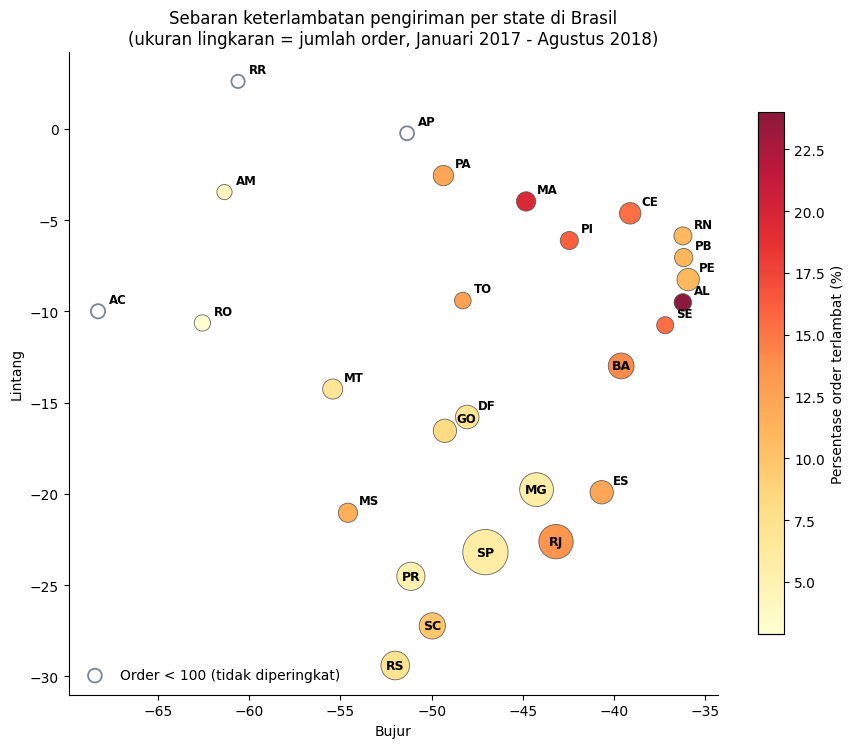

In [ ]:
# Peta bubble: warna = persentase terlambat, ukuran = jumlah order

cukup = peta_state['total_order'] >= 100
ukuran = 60 + np.sqrt(peta_state['total_order']) * 5   # skala akar agar state kecil tetap terlihat

fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(peta_state.loc[~cukup, 'lng'], peta_state.loc[~cukup, 'lat'],
           s=ukuran[~cukup], facecolors='none', edgecolors='#7A8594', linewidths=1.3,
           label='Order < 100 (tidak diperingkat)')

sc = ax.scatter(peta_state.loc[cukup, 'lng'], peta_state.loc[cukup, 'lat'],
                s=ukuran[cukup], c=peta_state.loc[cukup, 'persen_terlambat'],
                cmap='YlOrRd', edgecolors='#555555', linewidths=0.6, alpha=0.9)

for _, r in peta_state.iterrows():
    if r['total_order'] >= 3000:      # lingkaran besar: label di tengah
        ax.annotate(r['customer_state'], (r['lng'], r['lat']), ha='center', va='center',
                    fontsize=9, fontweight='bold')
    else:                              # lingkaran kecil: label digeser agar tidak menutupi
        ax.annotate(r['customer_state'], (r['lng'], r['lat']), xytext=(8, 6),
                    textcoords='offset points', fontsize=8.5, fontweight='bold')

cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label('Persentase order terlambat (%)')

ax.set_xlabel('Bujur')
ax.set_ylabel('Lintang')
ax.set_title('Sebaran keterlambatan pengiriman per state di Brasil\n(ukuran lingkaran = jumlah order, Januari 2017 - Agustus 2018)', fontsize=12)
ax.legend(loc='lower left', frameon=False)
ax.set_aspect('equal')
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Dari petanya, masalah keterlambatan ternyata punya "alamat" yang jelas. Lingkaran merah paling gelap berkumpul di sisi timur laut Brasil, yaitu Alagoas (24,0%), Maranhão (19,6%), Piauí (16,0%), Ceará, dan Sergipe (sama-sama sekitar 15,4%). Kalau seluruh sembilan state di kawasan itu digabung, sekitar 14,4% pesanannya terlambat, hampir dua kali lipat dibanding state lain di luar kawasan tersebut yang hanya sekitar 7,5%.
- Kebalikannya terjadi di wilayah tenggara dan selatan yang menjadi pusat pesanan. São Paulo (SP) menyumbang sekitar 42% dari seluruh order, tapi hanya 5,9% yang terlambat. Minas Gerais (5,6%) dan Paraná (5,0%) juga rapi. Artinya pengiriman ke area padat pesanan sudah berjalan cukup baik, dan masalahnya ada di daerah yang jauh dari sana.
- Ada satu pengecualian yang patut dicermati: Rio de Janeiro (RJ). Letaknya di tenggara dan ordernya banyak (sekitar 12 ribu), tapi keterlambatannya 13,5%, setara dengan state di timur laut. Karena volumenya besar, jumlah order terlambat di RJ (sekitar 1.664) bahkan lebih banyak daripada gabungan beberapa state timur laut.
- Jadi ada dua cara melihat prioritas: state dengan persentase tertinggi (Alagoas, Maranhão, Piauí), atau state dengan jumlah order terlambat terbanyak (SP dan RJ). Dua-duanya layak dipertimbangkan, tergantung sumber daya yang tersedia.
- Satu catatan: titik tiap state di peta dihitung dari rata-rata koordinat kode pos, jadi posisinya perkiraan kasar. Cukup untuk membaca pola antarwilayah, tapi bukan untuk mengukur jarak.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Keterlambatan terbukti berjalan beriringan dengan kepuasan pelanggan yang lebih rendah. Selama Januari 2017 - Agustus 2018, order yang tiba tepat waktu rata-rata mendapat skor review 4,29, sedangkan order yang terlambat hanya 2,57. Selisihnya sekitar 1,72 poin, dan sekitar 8,1% dari seluruh order (7.822 dari 96.203) termasuk yang terlambat. Keterlambatan paling sering terjadi di Alagoas (24,0%), disusul Maranhão (19,6%) dan Piauí (16,0%), jauh di atas rata-rata keseluruhan. Peta geospasial menunjukkan pola yang jelas: kawasan timur laut Brasil rata-rata mencatat sekitar 14,4% order terlambat, hampir dua kali lipat state lain (sekitar 7,5%). Rio de Janeiro juga mencolok (13,5%) karena volumenya besar, sedangkan São Paulo, yang menyumbang sekitar 42% order, justru rapi di angka 5,9%.
- **Conclusion pertanyaan 2:** Pada Januari-Agustus 2018, sepuluh kategori dengan revenue terbesar adalah `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`, `housewares`, `furniture_decor`, `auto`, `baby`, dan `cool_stuff`. Posisi teratas ditempati `health_beauty` dengan sekitar 756 ribu BRL. Revenue seluruh marketplace naik sekitar 141% dibanding periode yang sama di 2017, sehingga kenaikan besar di banyak kategori sebagian mencerminkan pasar yang membesar. Dengan patokan itu, `baby` (sekitar 269%), `watches_gifts` (sekitar 242%), `health_beauty` (sekitar 210%), `housewares` (sekitar 207%), dan `auto` (sekitar 174%) tumbuh lebih cepat dari pasar. Sebaliknya `bed_bath_table`, `sports_leisure`, `computers_accessories`, `furniture_decor`, dan `cool_stuff` tumbuh di bawahnya, dan `cool_stuff` nyaris stagnan di sekitar 10%.

**Rekomendasi Action Item:**
- **Fokuskan perbaikan logistik ke wilayah yang paling bermasalah.** Mulai dari Alagoas, Maranhão, dan Piauí karena persentase keterlambatannya tertinggi, lalu Rio de Janeiro karena jumlah order terlambatnya besar. Evaluasi kurir dan rute di wilayah tersebut, atau pertimbangkan menambah mitra pengiriman lokal.
- **Tinjau ulang estimasi waktu pengiriman untuk kawasan timur laut.** Karena "terlambat" dihitung terhadap tanggal estimasi, estimasi yang terlalu optimistis di wilayah itu ikut menggelembungkan angka keterlambatan. Memberi estimasi yang lebih realistis, plus pemberitahuan proaktif kepada pelanggan saat pesanan tertunda, bisa menjaga ekspektasi dan melindungi skor review.
- **Pantau keterlambatan per state secara rutin.** Pasang metrik persentase terlambat per state di dashboard bulanan, supaya perbaikannya bisa diukur dari waktu ke waktu dan pola yang menyimpang cepat terlihat.
- **Dorong kategori yang tumbuh cepat.** `health_beauty`, `watches_gifts`, dan `baby` layak mendapat prioritas stok dan promosi, karena sudah besar dan masih melaju di atas rata-rata pasar.
- **Cari tahu penyebab kategori yang tertinggal.** Terutama `cool_stuff`, yang hampir tidak tumbuh. Perlu dicek apakah penyebabnya stok, harga, persaingan, atau seller yang berkurang, sebelum memutuskan strategi lanjutannya.

# Membuat File 'main_data.csv' untuk Dashboard

In [ ]:
# Titik pusat tiap state (untuk peta di dashboard)
pusat_state = geo_zip.groupby('state').agg(state_lat=('lat', 'mean'), state_lng=('lng', 'mean')).reset_index()

# Satu tabel gabungan berisi semua yang dibutuhkan dashboard
main_data = (df_q1[['order_id', 'order_purchase_timestamp', 'customer_state', 'review_score', 'terlambat']]
             .merge(order_items[['order_id', 'product_id', 'price']], on='order_id', how='inner')
             .merge(products_clean[['product_id', 'product_category_name_english']], on='product_id', how='left')
             .merge(pusat_state, left_on='customer_state', right_on='state', how='left')
             .drop(columns=['product_id', 'state'])
             .rename(columns={'order_purchase_timestamp': 'tanggal_order',
                              'product_category_name_english': 'kategori_produk'}))

main_data['state_lat'] = main_data['state_lat'].round(3)
main_data['state_lng'] = main_data['state_lng'].round(3)

print('Ukuran:', main_data.shape)
print('Order unik:', main_data['order_id'].nunique())
print(main_data.isna().sum())
main_data.head()

Ukuran: (109872, 9)
Order unik: 96203
order_id             0
tanggal_order        0
customer_state       0
review_score       823
terlambat            0
price                0
kategori_produk      0
state_lat            0
state_lng            0
dtype: int64


,order_id,tanggal_order,customer_state,review_score,terlambat,price,kategori_produk,state_lat,state_lng
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,SP,4.0,False,29.99,housewares,-23.191,-47.054
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,BA,4.0,False,118.70,perfumery,-12.990,-39.615
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,GO,5.0,False,159.90,auto,-16.544,-49.274
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,RN,5.0,False,45.00,pet_shop,-5.865,-36.233
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,SP,5.0,False,19.90,stationery,-23.191,-47.054


In [ ]:
main_data.to_csv('main_data.csv', index=False)

from google.colab import files
files.download('main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>